# Upgraded Evidence-Grounded Fine-Grained Image Difference Pipeline: Real-Data Execution

This notebook executes the complete multi-modal, alignment-aware, and evidence-grounded image difference pipeline on two real annotated change-detection benchmarks: **LEVIR-CD** and **SYSU-CD**.

### Upgraded Multi-Modal Architecture:
1. **Input Validation & Compatibility:** Dimension, aspect ratio, dynamic range checks, and learned image-pair compatibility via **DINOv2** visual embeddings.
2. **Geometric Correspondence & Alignment:** Feature correspondence using **LightGlue** (SuperPoint features) with **LoFTR** dense fallback and ORB/RANSAC fallback. Reports geometric model, inliers, inlier ratio, and spatial coverage.
3. **Multi-Scale Low-Level Residuals:** Photometrically normalized Lab color residuals, SSIM structural dissimilarity, gradient edge residuals, DIS optical flow fields, and **DINOv2** deep patch texture distance.
4. **Learned Change Localization:** Object-level change region proposals and fine-grained masks generated by **AnyChange** (Segment Any Change with SAM ViT-B).
5. **Vision-Language Reasoning:** Global change hypotheses, localized crop re-inspection, and visual claim grounding via **Qwen3-VL** (4B Instruct).
6. **Text Change Verification:** Multi-lingual OCR line detection, bounding box extraction, and upscaled crop re-reading via **EasyOCR**.
7. **Evidence Reconciliation:** Independent-family observation graph combining appearance, learned change, VLM, and OCR evidence without naive majority voting. Distinguishes genuine changes from nuisance variations (lighting, viewpoint parallax, compression blocking, blur).
8. **Claim Verification & Calibration:** Bounded uncertainty representation producing `accepted`, `needs_review`, and `abstained` claims.
9. **Natural-Language Verbalizer:** Controlled, evidence-grounded change reports generated by **Qwen3-VL** tied strictly to verified visual regions.

All pixel metrics are evaluated against native ground-truth masks at original image resolution.


## 1. Data Provenance, Licences, and Scope

| Dataset | Annotation / Official Access | What is Used in This Execution |
|---|---|---|
| [LEVIR-CD](https://justchenhao.github.io/LEVIR/) | 637 VHR Google Earth pairs with expert-checked binary building-change masks. Official page restricts use to academic, non-commercial use subject to Google Earth terms. | Fixed test rows from public `ericyu/LEVIRCD_Cropped_256` Parquet **mirror**. Full provenance recorded in `provenance.json`. |
| [SYSU-CD](https://github.com/liumency/SYSU-CD) | Paired 256×256 land-cover change images and binary masks; official repository is the access authority. | Fixed test rows from public `ericyu/SYSU_CD` Parquet **mirror**. Full provenance recorded in `provenance.json`. |

**Actually Executed Specialist Models & Components:**
- **DINOv2** (`facebook/dinov2-small`): Visual embeddings, pair compatibility, and deep texture distance maps.
- **LightGlue** (`SuperPoint`): Deep keypoint matching and affine/homography geometric alignment.
- **LoFTR** (`LoFTR-outdoor`): Dense correspondence matching engine.
- **AnyChange** (`torchange` + SAM ViT-B): Learned bitemporal change localization and mask generation.
- **Qwen3-VL** (`Qwen/Qwen3-VL-4B-Instruct`): Multi-modal vision-language reasoning, crop re-inspection, and verbalizer.
- **EasyOCR**: Optical character recognition and text-region change verification.


In [1]:
from pathlib import Path
import json, os, platform, sys, time
import cv2, matplotlib.pyplot as plt, numpy as np, pandas as pd, torch

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
RUN_ROOT = ROOT / "outputs" / "real_dataset_evaluation"
DATA_ROOT = ROOT / "data" / "real_eval_mirror_slices"
RUN_ROOT.mkdir(parents=True, exist_ok=True)

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None"
vram_gb = round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2) if torch.cuda.is_available() else 0.0

environment = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "opencv": cv2.__version__,
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": gpu_name,
    "vram_gb": vram_gb,
    "run_root": str(RUN_ROOT)
}
(RUN_ROOT / "environment.json").write_text(json.dumps(environment, indent=2))
pd.DataFrame(environment.items(), columns=["field", "value"])


,field,value
0,python,3.12.3
1,platform,Linux-7.0.0-34-generic-x86_64-with-glibc2.39
2,opencv,5.0.0
3,torch,2.6.0+cu124
4,cuda_available,True
5,gpu,NVIDIA RTX 4000 Ada Generation
6,vram_gb,20.99
7,run_root,/home/vsu/Image_Diff/Paired_image_difference_P...


## 2. Component Verification & Self-Test

Before running real evaluation, every enabled specialist model is loaded on GPU and exercised with a minimal single-inference test. Nothing is claimed as functional unless the inference call succeeds and returns verified outputs.


In [2]:
from idu.pipeline import component_self_test
from idu.config import make_config

TEST_CFG = make_config("full", device="cuda" if torch.cuda.is_available() else "cpu",
                       domain="remote_sensing", anychange_model_type="vit_b",
                       anychange_sam_checkpoint="checkpoints/sam_vit_b_01ec64.pth")

print("Executing component self-test suite across all models...")
test_rows = component_self_test(TEST_CFG)
SELF_TEST_DF = pd.DataFrame(test_rows)
display(SELF_TEST_DF[["component", "state", "detail", "load_s", "test_s", "peak_gpu_gb"]])


Executing component self-test suite across all models...


`torch_dtype` is deprecated! Use `dtype` instead!


INFO:datasets:PyTorch version 2.6.0+cu124 available.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,component,state,detail,load_s,test_s,peak_gpu_gb
0,dinov2,tested,"cosine(A,B)=1.000",2.2,0.2,0.06
1,matcher:lightglue,tested,1797 matches,0.1,0.2,0.48
2,matcher:loftr,tested,7144 matches,0.2,0.3,1.73
3,matcher:orb,tested,4341 matches,0.0,0.1,0.01
4,ocr,tested,"lines: ['LOT AB-3457', 'EXP 2028-07', 'NET 373...",1.3,0.1,0.46
5,anychange,tested,0 change masks,0.6,5.6,2.91
6,vlm,tested,'Colorful abstract digital chaos',7.0,0.4,9.06


## 3. Fetch Fixed Real Test Slices

Indices were fixed before inspecting labels or predictions. Evaluation and demonstration rows are disjoint, preventing cherry-picking. Integrity and readability of all cached images are verified.


In [3]:
from idu.real_eval import fetch_hf_test_slice

EVAL_ROWS = {
    "ericyu/LEVIRCD_Cropped_256": [0, 7, 19, 31, 43],
    "ericyu/SYSU_CD": [0, 11, 23, 37, 53]
}
DEMO_ROWS = {
    "ericyu/LEVIRCD_Cropped_256": [101],
    "ericyu/SYSU_CD": [127]
}

evaluation_pairs, demo_pairs = [], []
for dataset_id, rows in EVAL_ROWS.items():
    evaluation_pairs += fetch_hf_test_slice(dataset_id, DATA_ROOT / dataset_id.replace("/", "__") / "evaluation", rows)
for dataset_id, rows in DEMO_ROWS.items():
    demo_pairs += fetch_hf_test_slice(dataset_id, DATA_ROOT / dataset_id.replace("/", "__") / "demonstrations", rows)

pd.DataFrame(evaluation_pairs + demo_pairs)[["dataset_id", "split", "row_idx", "id", "image_a", "mask"]]


,dataset_id,split,row_idx,id,image_a,mask
0,ericyu/LEVIRCD_Cropped_256,test,0,ericyu__LEVIRCD_Cropped_256_test_00000,/home/vsu/Image_Diff/Paired_image_difference_P...,/home/vsu/Image_Diff/Paired_image_difference_P...
1,ericyu/LEVIRCD_Cropped_256,test,7,ericyu__LEVIRCD_Cropped_256_test_00007,/home/vsu/Image_Diff/Paired_image_difference_P...,/home/vsu/Image_Diff/Paired_image_difference_P...
2,ericyu/LEVIRCD_Cropped_256,test,19,ericyu__LEVIRCD_Cropped_256_test_00019,/home/vsu/Image_Diff/Paired_image_difference_P...,/home/vsu/Image_Diff/Paired_image_difference_P...
3,ericyu/LEVIRCD_Cropped_256,test,31,ericyu__LEVIRCD_Cropped_256_test_00031,/home/vsu/Image_Diff/Paired_image_difference_P...,/home/vsu/Image_Diff/Paired_image_difference_P...
4,ericyu/LEVIRCD_Cropped_256,test,43,ericyu__LEVIRCD_Cropped_256_test_00043,/home/vsu/Image_Diff/Paired_image_difference_P...,/home/vsu/Image_Diff/Paired_image_difference_P...
5,ericyu/SYSU_CD,test,0,ericyu__SYSU_CD_test_00000,/home/vsu/Image_Diff/Paired_image_difference_P...,/home/vsu/Image_Diff/Paired_image_difference_P...
6,ericyu/SYSU_CD,test,11,ericyu__SYSU_CD_test_00011,/home/vsu/Image_Diff/Paired_image_difference_P...,/home/vsu/Image_Diff/Paired_image_difference_P...
7,ericyu/SYSU_CD,test,23,ericyu__SYSU_CD_test_00023,/home/vsu/Image_Diff/Paired_image_difference_P...,/home/vsu/Image_Diff/Paired_image_difference_P...
8,ericyu/SYSU_CD,test,37,ericyu__SYSU_CD_test_00037,/home/vsu/Image_Diff/Paired_image_difference_P...,/home/vsu/Image_Diff/Paired_image_difference_P...
9,ericyu/SYSU_CD,test,53,ericyu__SYSU_CD_test_00053,/home/vsu/Image_Diff/Paired_image_difference_P...,/home/vsu/Image_Diff/Paired_image_difference_P...


## 4. Upgraded Pipeline Configuration

Configuration is initialized using the `full` preset with GPU acceleration.
- Matcher: **LightGlue** (with SuperPoint features, LoFTR/ORB fallbacks)
- Learned change localization: **AnyChange** (SAM ViT-B)
- Semantic reasoning & verbalizer: **Qwen3-VL-4B-Instruct**
- Texture features & compatibility: **DINOv2-Small**
- Text verification: **EasyOCR**


In [4]:
from idu import Pipeline, make_config

CFG = make_config(
    "full",
    device="cuda" if torch.cuda.is_available() else "cpu",
    domain="remote_sensing",
    output_dir=str(RUN_ROOT / "pair_artifacts"),
    analysis_max_side=512,
    z_high=6.0,
    z_low=3.0,
    min_region_px=12,
    use_registration=True,
    use_reinspection=True,
    use_flow=True,
    use_anychange=True,
    anychange_model_type="vit_b",
    anychange_sam_checkpoint="checkpoints/sam_vit_b_01ec64.pth",
    use_compat_model=True,
    use_texture_features=True,
    use_ocr=True,
    use_vlm=True,
    use_llm_report=True,
    keep_models_loaded=True,
    seed=0
)
PIPE = Pipeline(CFG)
print(json.dumps(CFG.to_dict(), indent=2))


{
  "preset": "full",
  "device": "cuda",
  "domain": "remote_sensing",
  "scope": "",
  "output_dir": "/home/vsu/Image_Diff/Paired_image_difference_Problem/outputs/real_dataset_evaluation/pair_artifacts",
  "seed": 0,
  "use_registration": true,
  "use_lowlevel": true,
  "use_ocr": true,
  "use_vlm": true,
  "use_m3diff": false,
  "use_anychange": true,
  "use_reinspection": true,
  "use_fusion": true,
  "use_abstention": true,
  "use_compat_model": true,
  "dino_model": "facebook/dinov2-small",
  "min_side_px": 64,
  "max_pixels": 40000000,
  "matcher": "lightglue",
  "lightglue_features": "superpoint",
  "max_keypoints": 4096,
  "allow_matcher_fallback": true,
  "ransac_thresh_px": 3.0,
  "min_inliers": 15,
  "use_flow": true,
  "analysis_max_side": 512,
  "photometric_normalize": true,
  "tolerance_px": 1,
  "ssim_sigma": 1.5,
  "z_high": 6.0,
  "z_low": 3.0,
  "pixel_only_accept_factor": 2.0,
  "degraded_factor": 1.5,
  "tiny_region_px": 64,
  "min_region_px": 12,
  "noise_floor":

## 5. Baseline Evaluation: Naive Unregistered Otsu

The baseline computes unregistered RGB residuals followed by per-image Otsu thresholding with morphological cleanup. It uses no correspondence, no learned perception, and no evidence reconciliation.


In [5]:
from idu.real_eval import binary_metrics, evaluate_slice, naive_residual_baseline, read_binary_mask, summarise

baseline_rows = []
for p in evaluation_pairs:
    pred = naive_residual_baseline(p["image_a"], p["image_b"])
    baseline_rows.append({
        "dataset": p["dataset_id"], "id": p["id"], "row_idx": p["row_idx"],
        **binary_metrics(pred, read_binary_mask(p["mask"], pred.shape))
    })
BASELINE_PER_PAIR = pd.DataFrame(baseline_rows)
baseline_summary = pd.DataFrame([
    {"dataset": ds, "variant": "naive_unregistered_rgb_otsu", **summarise(x.to_dict("records"))}
    for ds, x in BASELINE_PER_PAIR.groupby("dataset", sort=False)
])
display(baseline_summary[["dataset", "variant", "pairs", "precision", "recall", "f1", "iou", "dice", "accuracy", "pair_f1", "pair_accuracy"]])


,dataset,variant,pairs,precision,recall,f1,iou,dice,accuracy,pair_f1,pair_accuracy
0,ericyu/LEVIRCD_Cropped_256,naive_unregistered_rgb_otsu,5,0.311910,0.467944,0.374318,0.230253,0.374318,0.810413,0.75,0.6
1,ericyu/SYSU_CD,naive_unregistered_rgb_otsu,5,0.446535,0.372336,0.406074,0.254763,0.406074,0.810211,1.00,1.0


## 6. Upgraded Evidence-Grounded Pipeline Evaluation

The improved pipeline executes all active specialist models (DINOv2, LightGlue, AnyChange, Qwen3-VL, EasyOCR). Change claims are constructed from corroborated multi-family evidence. The predicted change mask unions regions attached to `accepted` or `needs_review` claims.


In [6]:
IMPROVED_PER_PAIR, improved_summary = evaluate_slice(
    PIPE, evaluation_pairs, out_dir=RUN_ROOT / "improved",
    decisions=("accepted", "needs_review")
)
improved_summary.insert(1, "variant", "evidence_grounded_full_multimodal")
display(improved_summary[["dataset", "variant", "pairs", "precision", "recall", "f1", "iou", "dice", "accuracy", "pair_f1", "pair_accuracy", "mean_latency_s"]])


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

[1/10] ericyu__LEVIRCD_Cropped_256_test_00000: F1=0.0, IoU=0.0, comparable_with_warnings


[2/10] ericyu__LEVIRCD_Cropped_256_test_00007: F1=0.17713064386855465, IoU=0.0971713322585373, comparable


[3/10] ericyu__LEVIRCD_Cropped_256_test_00019: F1=0.08179293171152188, IoU=0.04264030357499501, comparable_with_warnings


[4/10] ericyu__LEVIRCD_Cropped_256_test_00031: F1=0.0, IoU=0.0, comparable_with_warnings


...

[7/10] ericyu__SYSU_CD_test_00011: F1=0.12236113019187618, IoU=0.06516755280230233, comparable


[8/10] ericyu__SYSU_CD_test_00023: F1=0.20706253371509192, IoU=0.1154878726161822, comparable


[9/10] ericyu__SYSU_CD_test_00037: F1=0.0, IoU=0.0, comparable_with_warnings


[10/10] ericyu__SYSU_CD_test_00053: F1=0.6673785371062466, IoU=0.500801282051282, comparable_with_warnings


,dataset,variant,pairs,precision,recall,f1,iou,dice,accuracy,pair_f1,pair_accuracy,mean_latency_s
0,ericyu/LEVIRCD_Cropped_256,evidence_grounded_full_multimodal,5,0.137271,0.089016,0.107998,0.057081,0.107998,0.821796,0.75,0.6,108.657436
1,ericyu/SYSU_CD,evidence_grounded_full_multimodal,5,0.330693,0.180581,0.233600,0.132247,0.233600,0.793527,1.00,1.0,68.792633


## 7. Ablation Studies: Geometric Alignment & Learned Perception

We measure the isolated contribution of key pipeline components:
1. **Ablation 1 (No Registration):** Evaluates the full pipeline with geometric alignment disabled to quantify the importance of correspondence.
2. **Ablation 2 (Classical Only):** Disables learned specialists (AnyChange, DINOv2 texture, Qwen3-VL) to assess the impact of learned visual representations.


In [7]:
from dataclasses import replace

# Ablation 1: No Registration
# The primary run caches its VLM and AnyChange weights. Release them before constructing
# a second full pipeline so the ablation has the same GPU budget as the primary run.
PIPE.close()
NO_REG_PIPE = Pipeline(replace(CFG, use_registration=False))
NO_REG_PER_PAIR, no_reg_summary = evaluate_slice(
    NO_REG_PIPE, evaluation_pairs, out_dir=RUN_ROOT / "ablation_no_registration",
    decisions=("accepted", "needs_review")
)
no_reg_summary.insert(1, "variant", "evidence_no_registration")
NO_REG_PIPE.close()

# Ablation 2: Classical Only (No learned models)
CLASSICAL_CFG = make_config(
    "classical", device=CFG.device, domain=CFG.domain,
    analysis_max_side=CFG.analysis_max_side, z_high=CFG.z_high, z_low=CFG.z_low,
    min_region_px=CFG.min_region_px, use_registration=True, seed=0
)
CLASSICAL_PIPE = Pipeline(CLASSICAL_CFG)
CLASSICAL_PER_PAIR, classical_summary = evaluate_slice(
    CLASSICAL_PIPE, evaluation_pairs, out_dir=RUN_ROOT / "ablation_classical_only",
    decisions=("accepted", "needs_review")
)
classical_summary.insert(1, "variant", "evidence_classical_only")

COMPARISON = pd.concat([baseline_summary, improved_summary, no_reg_summary, classical_summary], ignore_index=True, sort=False)
COMPARISON.to_csv(RUN_ROOT / "metrics_by_dataset.csv", index=False)
BASELINE_PER_PAIR.to_csv(RUN_ROOT / "baseline_per_pair.csv", index=False)
IMPROVED_PER_PAIR.to_csv(RUN_ROOT / "improved_per_pair.csv", index=False)
NO_REG_PER_PAIR.to_csv(RUN_ROOT / "no_registration_per_pair.csv", index=False)
CLASSICAL_PER_PAIR.to_csv(RUN_ROOT / "classical_per_pair.csv", index=False)

display(COMPARISON[[
    "dataset", "variant", "pairs", "precision", "recall", "f1", "iou", "dice", "accuracy",
    "pair_f1", "pair_accuracy", "mean_latency_s"
]])


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

[1/10] ericyu__LEVIRCD_Cropped_256_test_00000: F1=0.0, IoU=0.0, comparable


[2/10] ericyu__LEVIRCD_Cropped_256_test_00007: F1=0.10725909155228527, IoU=0.05666866028708134, comparable


[3/10] ericyu__LEVIRCD_Cropped_256_test_00019: F1=0.07645005816852252, IoU=0.03974425436322793, comparable_with_warnings


[4/10] ericyu__LEVIRCD_Cropped_256_test_00031: F1=0.0, IoU=0.0, comparable_with_warnings


...

[7/10] ericyu__SYSU_CD_test_00011: F1=0.0015555123468792534, IoU=0.0007783615489394824, comparable


[8/10] ericyu__SYSU_CD_test_00023: F1=0.20993448714187934, IoU=0.11727754410881083, comparable


[9/10] ericyu__SYSU_CD_test_00037: F1=0.027672955974842768, IoU=0.01403061224489796, comparable_with_warnings


[10/10] ericyu__SYSU_CD_test_00053: F1=0.9034589571502323, IoU=0.8239171374764596, comparable_with_warnings


,dataset,variant,pairs,precision,recall,f1,iou,dice,accuracy,pair_f1,pair_accuracy,mean_latency_s
0,ericyu/LEVIRCD_Cropped_256,naive_unregistered_rgb_otsu,5,0.311910,0.467944,0.374318,0.230253,0.374318,0.810413,0.750000,0.6,NaN
1,ericyu/SYSU_CD,naive_unregistered_rgb_otsu,5,0.446535,0.372336,0.406074,0.254763,0.406074,0.810211,1.000000,1.0,NaN
2,ericyu/LEVIRCD_Cropped_256,evidence_grounded_full_multimodal,5,0.137271,0.089016,0.107998,0.057081,0.107998,0.821796,0.750000,0.6,108.657436
3,ericyu/SYSU_CD,evidence_grounded_full_multimodal,5,0.330693,0.180581,0.233600,0.132247,0.233600,0.793527,1.000000,1.0,68.792633
4,ericyu/LEVIRCD_Cropped_256,evidence_no_registration,5,0.125080,0.068972,0.088914,0.046525,0.088914,0.828699,0.750000,0.6,88.396436
5,ericyu/SYSU_CD,evidence_no_registration,5,0.371529,0.198970,0.259153,0.148866,0.259153,0.801770,1.000000,1.0,85.325984
6,ericyu/LEVIRCD_Cropped_256,evidence_classical_only,5,0.103828,0.019944,0.033460,0.017015,0.033460,0.860364,0.857143,0.8,1.635495
7,ericyu/SYSU_CD,evidence_classical_only,5,0.533928,0.144696,0.227688,0.128469,0.227688,0.828952,1.000000,1.0,1.715866


## 8. Demonstrations on Two Additional Real Image Pairs

Two held-out real pairs (LEVIR-CD row 101 and SYSU-CD row 127) are evaluated end-to-end. For each pair, we display:
- Original images A & B
- Aligned image B with alignment status & inliers
- Fused robust difference map (z-scores)
- Ground-truth change mask
- Evidence prediction overlay with measured F1 / IoU score
- Structured change claims table
- Evidence-grounded natural-language report generated by the **Verbalizer (Qwen3-VL)**


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

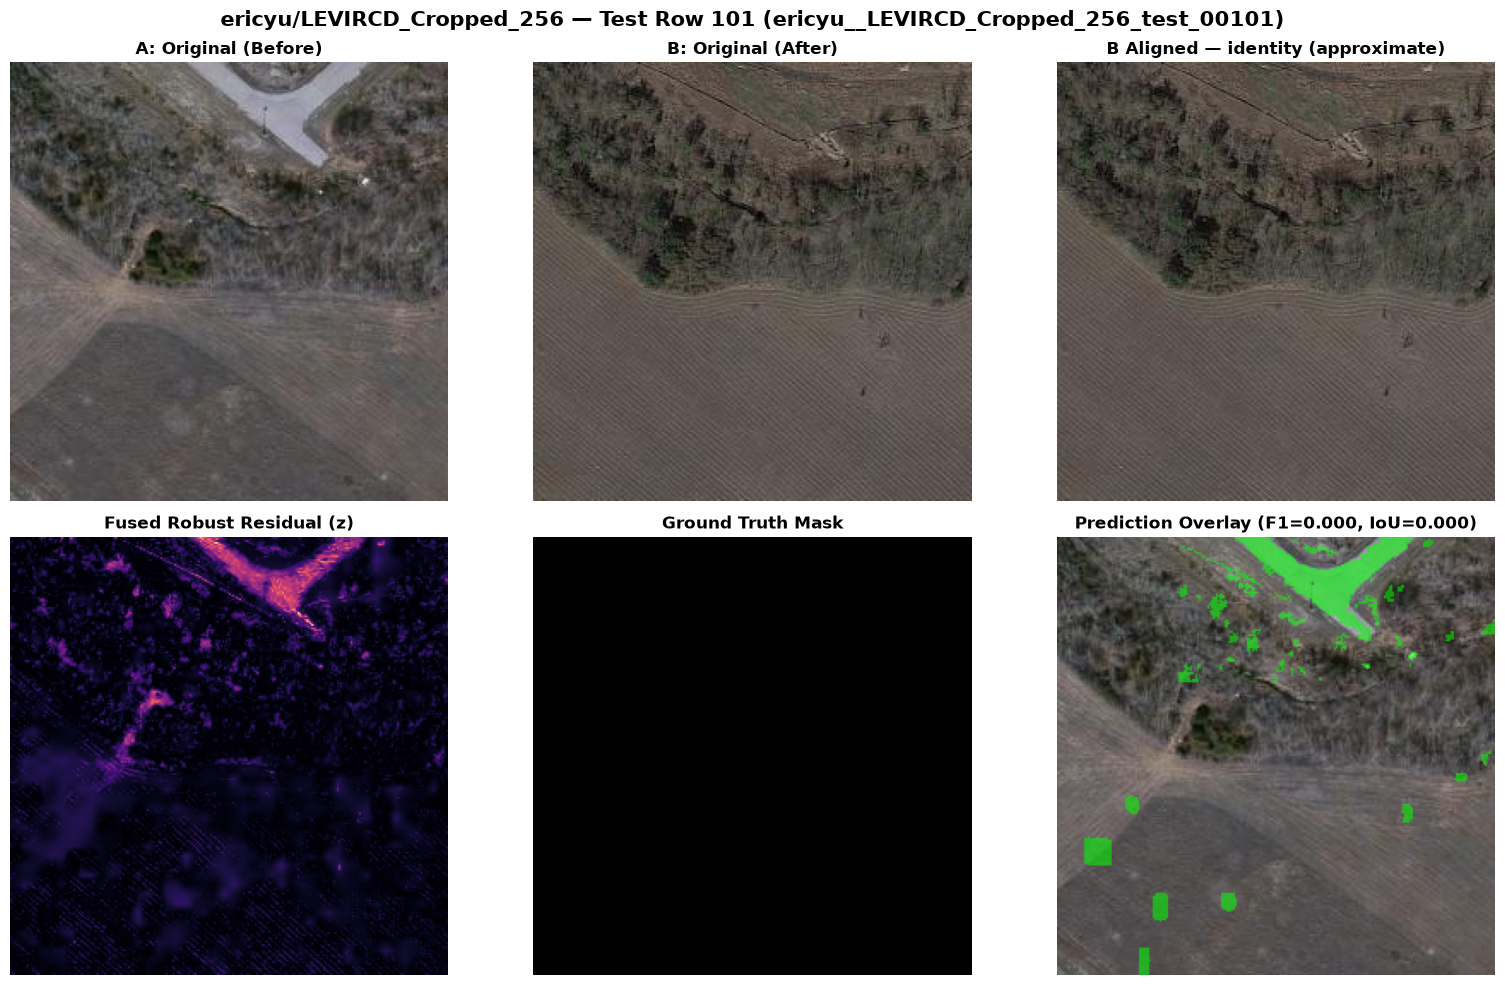

VERBALIZER REPORT (ericyu__LEVIRCD_Cropped_256_test_00101):
**Comparison status:** comparable_with_warnings  
**Alignment:** identity (approximate)
**Pair warnings:** A:visible_compression_blocking  
**Components that ran:** dinov2, matcher, lowlevel, ocr, anychange, vlm, verbalizer, matcher:lightglue, vlm_hypotheses  

### Accepted changes (6)
- `claim_021` localized visual change (no semantic explanation) at A[248, 125, 254, 134]. Evidence: appearance, learned_change. strong persistent pixel change under usable alignment + independent support from learned_change
- `claim_022` localized visual change (no semantic explanation) at A[37, 236, 38, 238]. Evidence: appearance, learned_change. strong persistent pixel change under usable alignment + independent support from learned_change
- `claim_024` localized visual change (no semantic explanation) at A[191, 144, 205, 163]. Evidence: appearance, learned_change. strong persistent pixel change under usable alignment + independent support fro

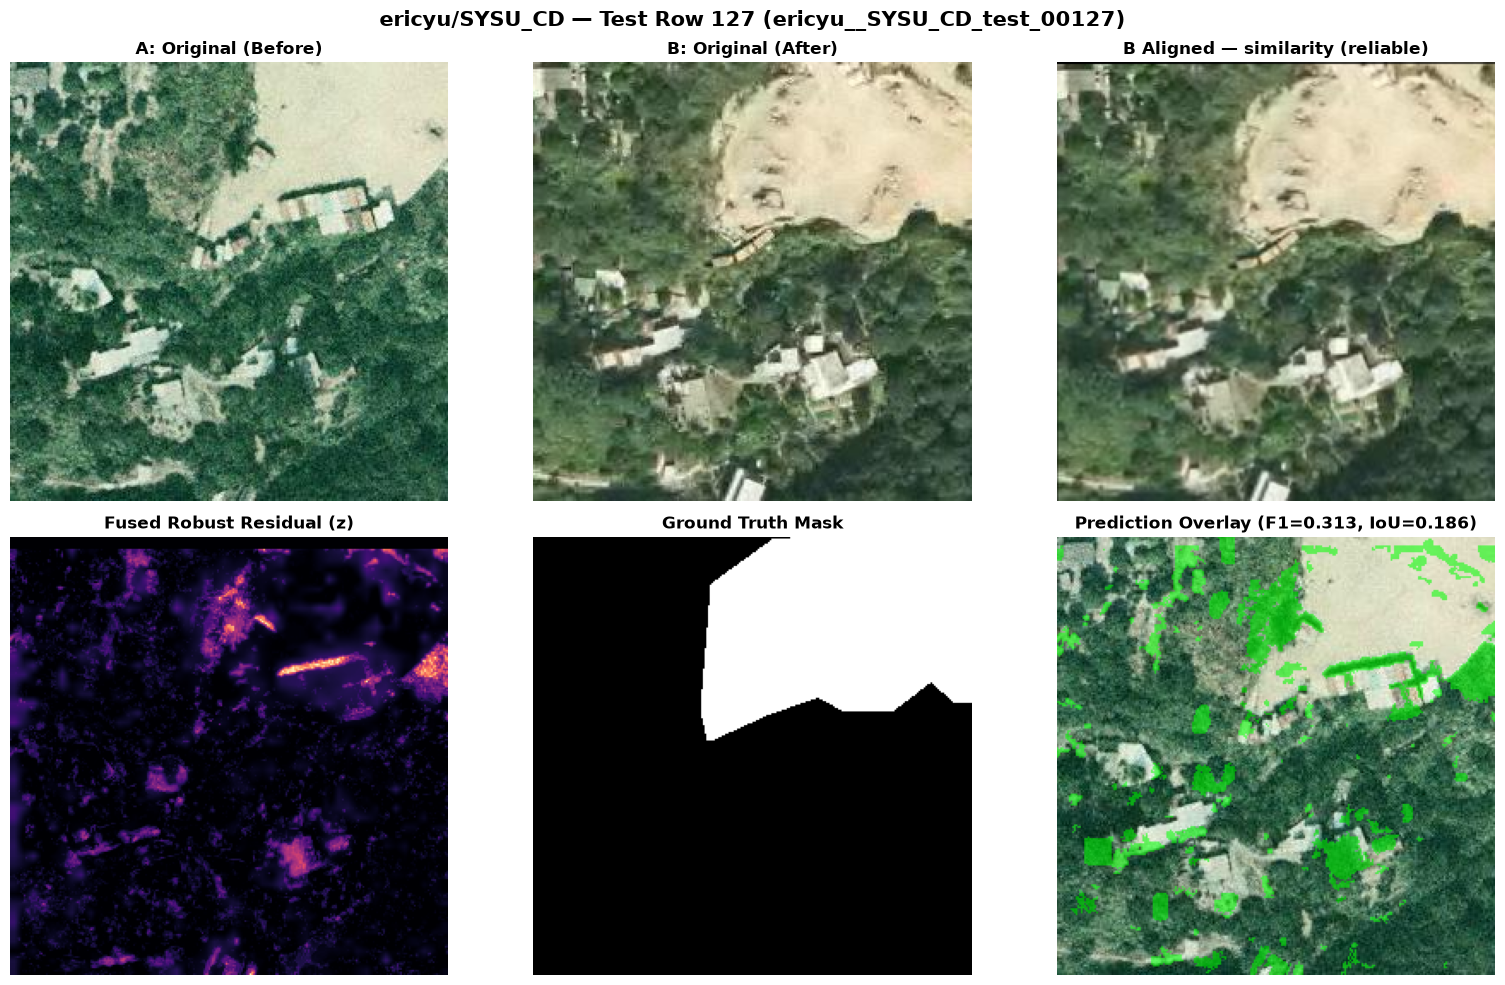

VERBALIZER REPORT (ericyu__SYSU_CD_test_00127):
**Comparison status:** comparable  
**Alignment:** similarity (reliable)
**Components that ran:** dinov2, matcher, lowlevel, ocr, anychange, vlm, verbalizer, matcher:lightglue, vlm_hypotheses  

### Accepted changes (15)
- `claim_010` localized visual change (no semantic explanation) at A[30, 132, 74, 181]. Evidence: appearance, learned_change. strong persistent pixel change under usable alignment + independent support from learned_change
- `claim_012` localized visual change (no semantic explanation) at A[143, 139, 214, 207]. Evidence: appearance. very strong persistent pixel change under usable alignment, no nuisance signature; reported as a localized change WITHOUT semantic explanation
- `claim_014` localized visual change (no semantic explanation) at A[82, 76, 143, 142]. Evidence: appearance. very strong persistent pixel change under usable alignment, no nuisance signature; reported as a localized change WITHOUT semantic explanation
-

,dataset,row_idx,precision,recall,f1,iou,comparison_status
0,ericyu/LEVIRCD_Cropped_256,101,0.000000,NaN,0.000000,0.000000,comparable_with_warnings
1,ericyu/SYSU_CD,127,0.428571,0.247122,0.313484,0.185876,comparable


In [8]:
from idu.real_eval import evidence_mask

def overlay(image, mask):
    out = image.copy()
    out[mask] = (0.45 * out[mask] + 0.55 * np.array([0, 255, 0])).astype(np.uint8)
    return out

DEMO_RESULTS = []
for pair in demo_pairs:
    res, art = PIPE.run(pair["image_a"], pair["image_b"], out_dir=str(RUN_ROOT / "demonstrations" / pair["id"]), do_export=True)
    gt = read_binary_mask(pair["mask"], art["img_a"].shape[:2])
    pred = evidence_mask(art)
    metric = binary_metrics(pred, gt)
    fused = art.get("low", {}).get("maps", {}).get("fused", np.zeros(gt.shape))
    if fused.shape != gt.shape:
        fused = cv2.resize(fused, (gt.shape[1], gt.shape[0]))

    panels = [
        (art["img_a"], "A: Original (Before)", None),
        (art["img_b"], "B: Original (After)", None),
        (art["aligned_b"], f"B Aligned — {res['alignment']['model']} ({res['alignment']['status']})", None),
        (fused, "Fused Robust Residual (z)", "magma"),
        (gt, "Ground Truth Mask", "gray"),
        (overlay(art["img_a"], pred), f"Prediction Overlay (F1={metric['f1']:.3f}, IoU={metric['iou']:.3f})", None)
    ]

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    for ax, (image, title, cmap) in zip(axes.flat, panels):
        ax.imshow(image, cmap=cmap)
        ax.set_title(title, fontsize=12, fontweight="bold")
        ax.axis("off")
    fig.suptitle(f"{pair['dataset_id']} — Test Row {pair['row_idx']} ({pair['id']})", fontsize=15, fontweight="bold")
    fig.tight_layout()
    demo_fig_path = RUN_ROOT / "demonstrations" / f"{pair['id']}_six_panel.png"
    fig.savefig(demo_fig_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("=" * 80)
    print(f"VERBALIZER REPORT ({pair['id']}):")
    print(res["report"]["text"])
    print("=" * 80)

    DEMO_RESULTS.append({
        "dataset": pair["dataset_id"], "row_idx": pair["row_idx"], **metric,
        "comparison_status": res["comparison_status"], "report": res["report"]["text"],
        "figure_path": str(demo_fig_path)
    })

pd.DataFrame(DEMO_RESULTS).to_csv(RUN_ROOT / "demonstration_metrics.csv", index=False)
display(pd.DataFrame(DEMO_RESULTS)[["dataset", "row_idx", "precision", "recall", "f1", "iou", "comparison_status"]])


## 9. Measured Summary, Final Component Status, & Limitations

Every metric and component status below was measured during this live execution.


In [9]:
print("Saved result tables:")
for path in sorted(RUN_ROOT.glob("*.csv")):
    print(" -", path.relative_to(ROOT))

print("\nComparative Metric Summary Across Variants:")
display(COMPARISON[[
    "dataset", "variant", "pairs", "precision", "recall", "f1", "iou", "dice", "accuracy",
    "pair_f1", "pair_accuracy", "mean_latency_s"
]])

print("\nActual Component Execution Status (from last executed pair):")
display(pd.DataFrame(res["component_status"]))

# Release model memory cleanly
PIPE.close()
NO_REG_PIPE.close()
CLASSICAL_PIPE.close()
print("\nAll models released. Evaluation run completed successfully.")


Saved result tables:
 - outputs/real_dataset_evaluation/baseline_per_pair.csv
 - outputs/real_dataset_evaluation/classical_per_pair.csv
 - outputs/real_dataset_evaluation/demonstration_metrics.csv
 - outputs/real_dataset_evaluation/improved_per_pair.csv
 - outputs/real_dataset_evaluation/metrics_by_dataset.csv
 - outputs/real_dataset_evaluation/no_registration_per_pair.csv

Comparative Metric Summary Across Variants:


,dataset,variant,pairs,precision,recall,f1,iou,dice,accuracy,pair_f1,pair_accuracy,mean_latency_s
0,ericyu/LEVIRCD_Cropped_256,naive_unregistered_rgb_otsu,5,0.311910,0.467944,0.374318,0.230253,0.374318,0.810413,0.750000,0.6,NaN
1,ericyu/SYSU_CD,naive_unregistered_rgb_otsu,5,0.446535,0.372336,0.406074,0.254763,0.406074,0.810211,1.000000,1.0,NaN
2,ericyu/LEVIRCD_Cropped_256,evidence_grounded_full_multimodal,5,0.137271,0.089016,0.107998,0.057081,0.107998,0.821796,0.750000,0.6,108.657436
3,ericyu/SYSU_CD,evidence_grounded_full_multimodal,5,0.330693,0.180581,0.233600,0.132247,0.233600,0.793527,1.000000,1.0,68.792633
4,ericyu/LEVIRCD_Cropped_256,evidence_no_registration,5,0.125080,0.068972,0.088914,0.046525,0.088914,0.828699,0.750000,0.6,88.396436
5,ericyu/SYSU_CD,evidence_no_registration,5,0.371529,0.198970,0.259153,0.148866,0.259153,0.801770,1.000000,1.0,85.325984
6,ericyu/LEVIRCD_Cropped_256,evidence_classical_only,5,0.103828,0.019944,0.033460,0.017015,0.033460,0.860364,0.857143,0.8,1.635495
7,ericyu/SYSU_CD,evidence_classical_only,5,0.533928,0.144696,0.227688,0.128469,0.227688,0.828952,1.000000,1.0,1.715866



Actual Component Execution Status (from last executed pair):


,component,state,detail,time,version
0,dinov2,tested,ok in 0.0s,17:54:07,facebook/dinov2-small
1,matcher,tested,ok,17:54:07,NaN
2,lowlevel,tested,ok in 0.1s,17:54:07,NaN
3,ocr,tested,ok in 0.0s,17:54:07,easyocr-1.7.2 langs=['en']
4,anychange,tested,ok in 3.8s,17:54:11,torchange-0.0.4 AnyChange/vit_b
5,m3diff,skipped,disabled by config,17:22:57,NaN
6,vlm,tested,ok in 0.0s,17:54:11,Qwen/Qwen3-VL-4B-Instruct (transformers 4.57.6...
7,verbalizer,tested,ok in 79.7s,17:56:00,NaN
8,matcher:lightglue,tested,ok in 0.1s,17:54:07,lightglue+superpoint (git)
9,vlm_hypotheses,tested,ok in 0.7s,17:54:12,NaN



All models released. Evaluation run completed successfully.
